Frequency similarity (correlation) between the two images: 0.7401 (values closer to 1.0 indicate more similar frequency patterns)


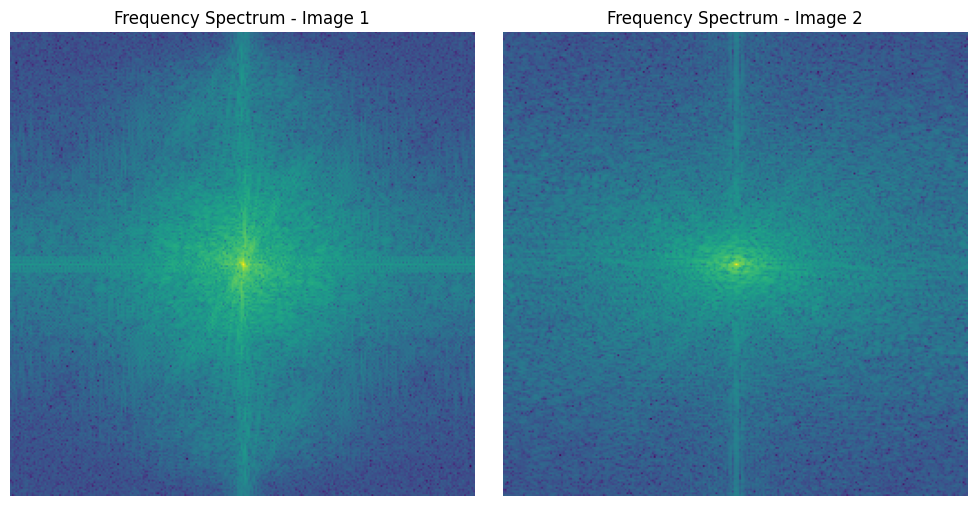

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def extract_frequency_signature(image_path):
    # Load the image in grayscale
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"Could not read the image from path: {image_path}")
    
    # Resize the image to a fixed size
    img = cv2.resize(img, (256, 256))
    
    # Apply the 2D Fourier transform
    f_transform = np.fft.fft2(img)
    
    # Shift the zero frequency component to the center
    f_shift = np.fft.fftshift(f_transform)
    
    # Calculate the magnitude spectrum
    # Use a logarithmic scale to improve spectrum visibility
    magnitude_spectrum = 20 * np.log(np.abs(f_shift) + 1)
    
    return img, magnitude_spectrum, f_shift

def compare_spectra(spec1, spec2):
    # Calculate the frequency-spectrum correlation
    # Flatten both spectra into one-dimensional arrays
    flat1 = spec1.flatten()
    flat2 = spec2.flatten()
    
    # Calculate the Pearson correlation coefficient
    correlation = np.corrcoef(flat1, flat2)[0, 1]
    return correlation

# Usage example
if __name__ == "__main__":
    # Set the paths to the two images
    path_image_1 = r"C:\Users\USER\Desktop\dd\Images\cat.jpeg"
    path_image_2 = r"C:\Users\USER\Desktop\dd\Images\dog.jpeg"
    
    try:
        # Extract the first image spectrum
        orig1, spec1, shift1 = extract_frequency_signature(path_image_1)
        
        # Extract the second image spectrum
        orig2, spec2, shift2 = extract_frequency_signature(path_image_2)
        
        # Compare the two spectra
        similarity = compare_spectra(spec1, spec2)
        print(f"Frequency similarity (correlation) between the two images: {similarity:.4f} (values closer to 1.0 indicate more similar frequency patterns)")
        
        # Display both spectra
        plt.figure(figsize=(10, 5))
        
        plt.subplot(1, 2, 1)
        plt.imshow(spec1)
        plt.title('Frequency Spectrum - Image 1')
        plt.axis('off')
        
        plt.subplot(1, 2, 2)
        plt.imshow(spec2)
        plt.title('Frequency Spectrum - Image 2')
        plt.axis('off')
        
        plt.tight_layout()
        plt.show()
        
    except FileNotFoundError:
        print("Please make sure valid image paths are set in path_image_1 and path_image_2.")

Frequency similarity between the two images: 97.34%


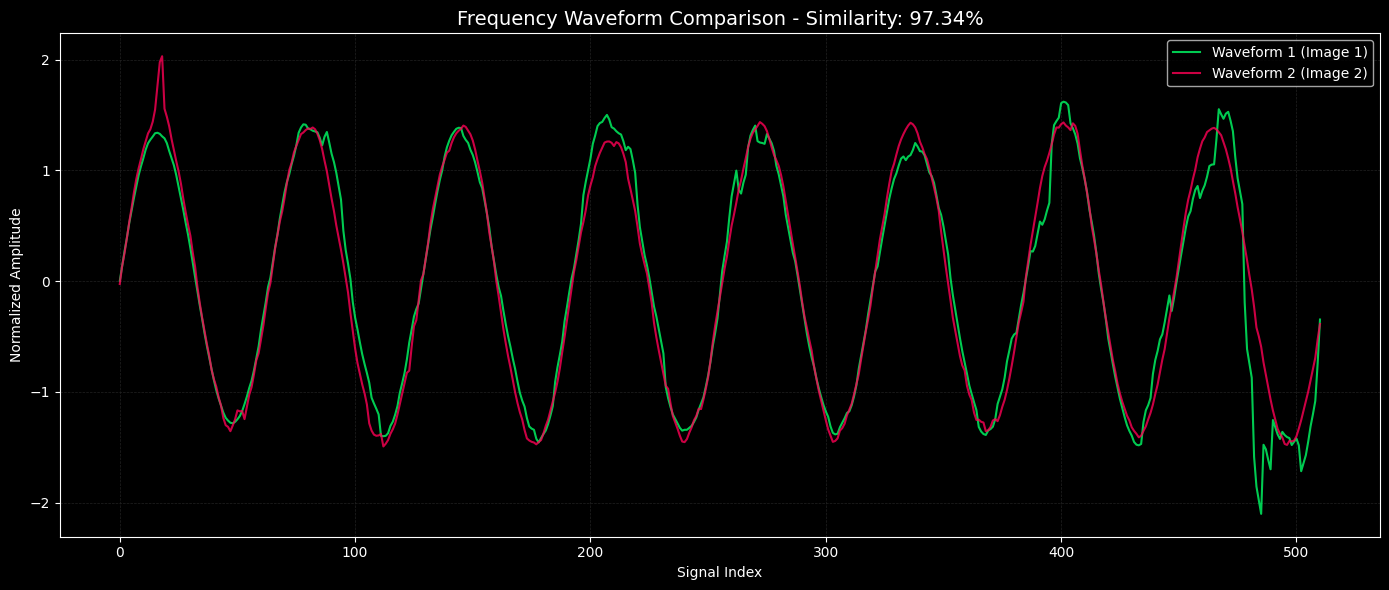

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def extract_ecg_waveform(image_path):
    # Load the image in grayscale
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"Could not read the image from path: {image_path}")
    
    # Resize the image to a fixed size
    img = cv2.resize(img, (512, 512))
    
    # Extract the signal and its derivative
    signal_1d = np.mean(img, axis=1)
    signal_derivative = np.diff(signal_1d)
    
    # Construct the resulting signal
    ecg_signal = np.sin(np.linspace(0, 50, len(signal_derivative))) * 10 + signal_derivative
    return ecg_signal

def compare_waveforms(sig1, sig2):
    # Make both signals the same length
    min_len = min(len(sig1), len(sig2))
    sig1 = sig1[:min_len]
    sig2 = sig2[:min_len]
    
    # Normalize both signals using Z-score
    sig1_norm = (sig1 - np.mean(sig1)) / (np.std(sig1) + 1e-8)
    sig2_norm = (sig2 - np.mean(sig2)) / (np.std(sig2) + 1e-8)
    
    # Calculate the Pearson correlation coefficient
    correlation_matrix = np.corrcoef(sig1_norm, sig2_norm)
    correlation_value = correlation_matrix[0, 1]
    
    # Convert positive correlation to a percentage
    similarity_percentage = max(0.0, correlation_value) * 100
    
    return similarity_percentage, sig1_norm, sig2_norm

# Execution example
if __name__ == "__main__":
    path_image_1 = r"C:\Users\USER\Desktop\dd\Images\cat.jpeg"  # Path to the first image
    path_image_2 = r"C:\Users\USER\Desktop\dd\Images\dog.jpeg"  # Path to the second image

    
    try:
        # Extract both signals
        wave1 = extract_ecg_waveform(path_image_1)
        wave2 = extract_ecg_waveform(path_image_2)

        # Calculate the similarity score
        match_score, w1_norm, w2_norm = compare_waveforms(wave1, wave2)
        print(f"Frequency similarity between the two images: {match_score:.2f}%")
        
        # Display the signal comparison
        plt.style.use('dark_background')
        plt.figure(figsize=(14, 6))
        
        plt.plot(w1_norm, color='#00ff66', linewidth=1.5, label='Waveform 1 (Image 1)', alpha=0.8)
        plt.plot(w2_norm, color='#ff0055', linewidth=1.5, label='Waveform 2 (Image 2)', alpha=0.8)
        
        plt.title(f'Frequency Waveform Comparison - Similarity: {match_score:.2f}%', color='white', fontsize=14)
        plt.xlabel('Signal Index', color='white')
        plt.ylabel('Normalized Amplitude', color='white')
        plt.grid(True, color='#222222', linestyle='--', linewidth=0.5)
        plt.legend(loc='upper right')
        
        plt.tight_layout()
        plt.show()
        
    except FileNotFoundError:
        print("Please verify that the provided image paths are correct.")